In [2]:
import os
import sys

# Run from the project root so `src` imports and relative data paths resolve.
if os.path.basename(os.getcwd()) == "jupyter_notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [3]:
import numpy as np
import torch 
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.true_constitutive_law import KinematicHardeningPlasticity
from src.ou_trajectories import generate_ou_trajectories, smooth_ou_trajectories
from src.neural_variational_ode import Dissipation, Energy, VariationalODESolver
from src.ou_trajectories import generate_ou_trajectories
from torch.utils.data import TensorDataset, DataLoader
from src.utilities import relative_l2_error


In [4]:
params = {'font.family': 'serif',
          'font.sans-serif': 'Times New Roman',
          'font.size': 14,
          'lines.linewidth': 2,
          'text.usetex': False,
          'xtick.top': True,
          'xtick.minor.visible': True,
          'ytick.minor.visible': True,
          'xtick.direction': 'in',
          'xtick.major.top': True,
          'xtick.major.bottom': True,
          'xtick.minor.top': True,
          'xtick.minor.bottom': True,
          'xtick.minor.width': 1,
          'xtick.major.width': 1,
          'xtick.minor.size': 3, 
          'xtick.major.size': 6,
          'ytick.right': True,
          'ytick.direction': 'in',
          'ytick.major.left': True,
          'ytick.major.right': True,
          'ytick.minor.left': True,
          'ytick.minor.right': True,
          'ytick.minor.width': 1,
          'ytick.major.width': 1,
          'ytick.minor.size': 3,
          'ytick.major.size': 6,
          'legend.frameon': False,
          'lines.markersize': 4.0,
          'axes.formatter.use_mathtext': True,
          'text.latex.preamble' : r'\usepackage{amsmath}',
          'text.usetex': True}
plt.rcParams.update(params)

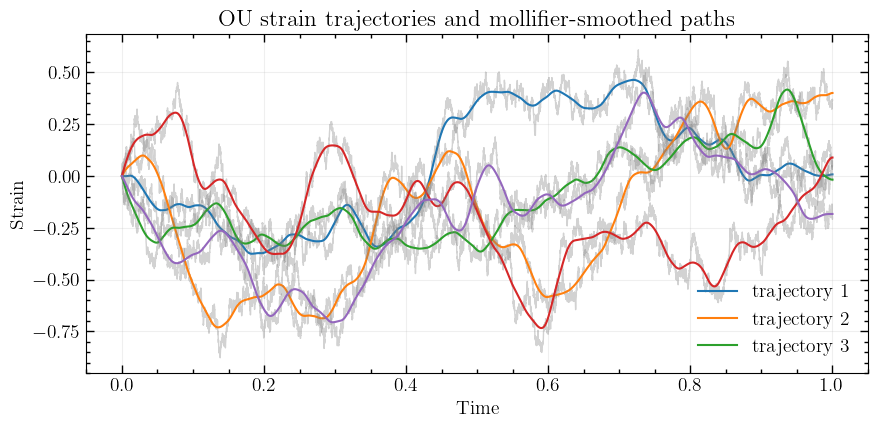

In [6]:
# 1. Sample strain trajectories with an OU process.
n_trajectories = 64
T = 1.0
dt = 1.0 / 12000.0
theta = 3.0
mu = 0.0
sigma = 1
x0 = 0.0

# 2. Smooth the sampled strain using the mollifier convolution.
mollifier_window = 601
times, strain_trajectories = generate_ou_trajectories(
    theta=theta,
    mu=mu,
    sigma=sigma,
    x0=x0,
    n_trajectories=n_trajectories,
    T=T,
    dt=dt,
    seed=41,
)
strain_trajectories_smooth = smooth_ou_trajectories(
    strain_trajectories,
    window_size=mollifier_window,
)

# 3. Visualize a few raw and smoothed strain trajectories.
fig, ax = plt.subplots(figsize=(9, 4.5))
for trajectory_index in range(min(5, n_trajectories)):
    ax.plot(
        times,
        strain_trajectories[trajectory_index],
        color="tab:gray",
        alpha=0.35,
        linewidth=1.0,
    )
    ax.plot(
        times,
        strain_trajectories_smooth[trajectory_index],
        linewidth=1.5,
        label=f"trajectory {trajectory_index + 1}" if trajectory_index < 3 else None,
    )
ax.set_xlabel("Time")
ax.set_ylabel("Strain")
ax.set_title("OU strain trajectories and mollifier-smoothed paths")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


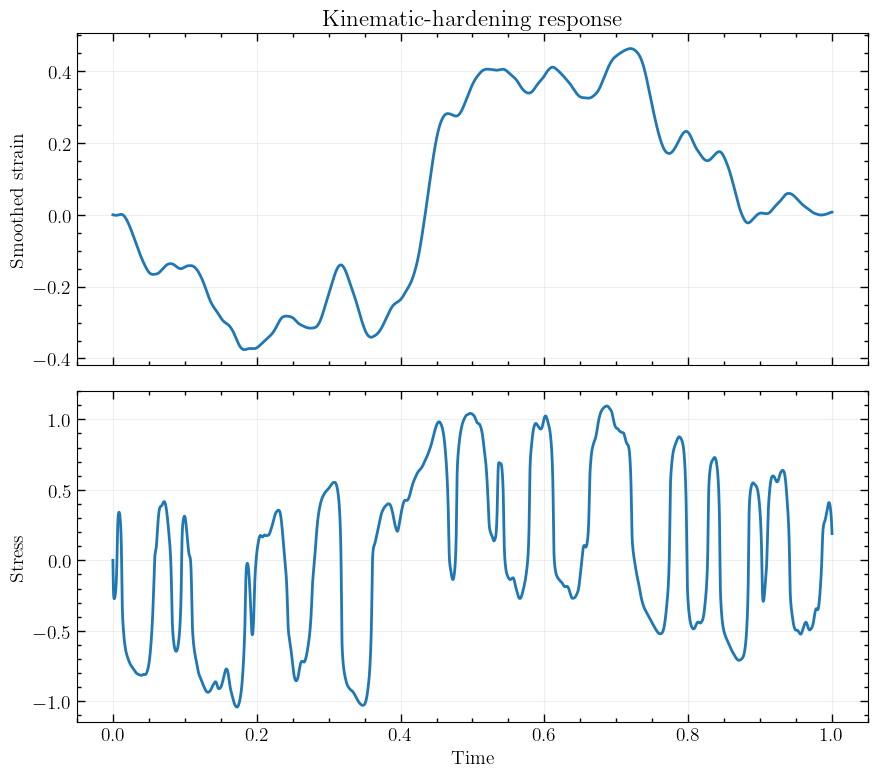

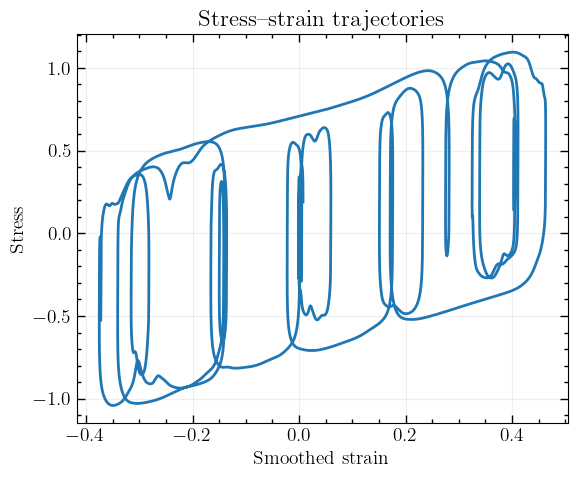

In [7]:
# 4. Solve for stress with the kinematic-hardening model.
E = 1000.0
H = 1.0
sigma_y = 0.5
rate_exponent = 0.5
kinematic_model = KinematicHardeningPlasticity(
    node_count=1,
    model_dt=dt,
    m=rate_exponent,
    E=E,
    H=H,
    sigma_y=sigma_y,
)

stress_trajectories = np.empty_like(strain_trajectories_smooth)
plastic_strain_trajectories = np.empty_like(strain_trajectories_smooth)
for trajectory_index, strain_path in enumerate(strain_trajectories_smooth):
    plastic_strain, stress_path = kinematic_model.stress_history(
        strain_path[:, np.newaxis]
    )
    plastic_strain_trajectories[trajectory_index] = plastic_strain[:, 0]
    stress_trajectories[trajectory_index] = stress_path[:, 0]

# 5. Visualize stress and strain histories, and the stress--strain response.
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for trajectory_index in range(min(1, n_trajectories)):
    axes[0].plot(times, strain_trajectories_smooth[trajectory_index])
    axes[1].plot(times, stress_trajectories[trajectory_index])
axes[0].set_ylabel("Smoothed strain")
axes[1].set_ylabel("Stress")
axes[1].set_xlabel("Time")
axes[0].set_title("Kinematic-hardening response")
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for trajectory_index in range(min(1, n_trajectories)):
    ax.plot(
        strain_trajectories_smooth[trajectory_index],
        stress_trajectories[trajectory_index],
    )
ax.set_xlabel("Smoothed strain")
ax.set_ylabel("Stress")
ax.set_title("Stress--strain trajectories")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
# 6. Learn W and D from the strain and stress samples without normalization.
strain_tensor = torch.as_tensor(strain_trajectories_smooth, dtype=torch.float32)
stress_tensor = torch.as_tensor(stress_trajectories, dtype=torch.float32)
training_dataset = TensorDataset(strain_tensor, stress_tensor)
train_loader = DataLoader(training_dataset, batch_size=16, shuffle=True)

energy_model = Energy(e_dim=1, xi_dim=1, hidden_sizes=(64,))
dissipation_model = Dissipation(xi_dim=1, hidden_sizes=(64,))
variational_solver = VariationalODESolver(energy_model, dissipation_model)
optimizer = torch.optim.Adam(variational_solver.parameters(), lr=1e-2)
loss_function = torch.nn.MSELoss()
training_losses = []
stress_relative_errors = []

In [9]:
n_epochs = 100
for epoch in tqdm(range(n_epochs), desc="Adjoint training", unit="epoch"):
    epoch_loss = 0.0
    epoch_stress_error = 0.0
    for strain_batch, stress_batch in train_loader:
        optimizer.zero_grad()
        loss, gradients, _, sigma_batch = variational_solver.compute_adjoint_gradients(
            strain_batch,
            stress_batch,
            dt=dt,
        )
        for parameter, gradient in zip(variational_solver.parameters(), gradients):
            parameter.grad = gradient / stress_batch.numel()
        optimizer.step()
        batch_size = strain_batch.shape[0]
        epoch_loss += (loss.item() / stress_batch.numel()) * batch_size
        epoch_stress_error += relative_l2_error(stress_batch, sigma_batch, times=times) * batch_size
    epoch_loss /= len(training_dataset)
    epoch_stress_error /= len(training_dataset)
    training_losses.append(epoch_loss)
    stress_relative_errors.append(epoch_stress_error)
    tqdm.write(
        f"Epoch {epoch + 1:3d}/{n_epochs}: loss = {epoch_loss:.6e}, "
        f"stress rel. error = {epoch_stress_error:.4e}"
    )
variational_solver.eval()


Adjoint training:   0%|          | 0/100 [00:00<?, ?epoch/s]

Epoch   1/100: loss = 1.936607e-04, stress rel. error = 2.8475e+00
Epoch   2/100: loss = 1.382290e-04, stress rel. error = 2.4166e+00
Epoch   3/100: loss = 9.816361e-05, stress rel. error = 2.0489e+00
Epoch   4/100: loss = 7.208563e-05, stress rel. error = 1.7564e+00
Epoch   5/100: loss = 5.254418e-05, stress rel. error = 1.5081e+00
Epoch   6/100: loss = 3.925786e-05, stress rel. error = 1.3127e+00
Epoch   7/100: loss = 3.069541e-05, stress rel. error = 1.1620e+00
Epoch   8/100: loss = 2.445790e-05, stress rel. error = 1.0439e+00
Epoch   9/100: loss = 2.053123e-05, stress rel. error = 9.6181e-01
Epoch  10/100: loss = 1.776648e-05, stress rel. error = 9.0044e-01


KeyboardInterrupt: 

In [38]:
with torch.enable_grad():
    xi_learned, stress_learned = variational_solver.solve(
        strain_tensor,
        dt=dt,
        create_graph=False,
    )
stress_learned = stress_learned.detach().cpu().numpy()
xi_learned = xi_learned.detach().cpu().numpy()

stress_errors_per_trajectory = relative_l2_error(
    stress_trajectories, stress_learned, times=times, reduction="none"
)
print(f"Stress relative L2 error: mean = {stress_errors_per_trajectory.mean():.4e}, "
      f"max = {stress_errors_per_trajectory.max():.4e}")

fig, ax = plt.subplots(figsize=(7, 4))
epochs = np.arange(1, len(stress_relative_errors) + 1)
ax.semilogy(epochs, stress_relative_errors)
ax.set_xlabel("Epoch")
ax.set_ylabel(r"Stress relative $L^2$ error")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


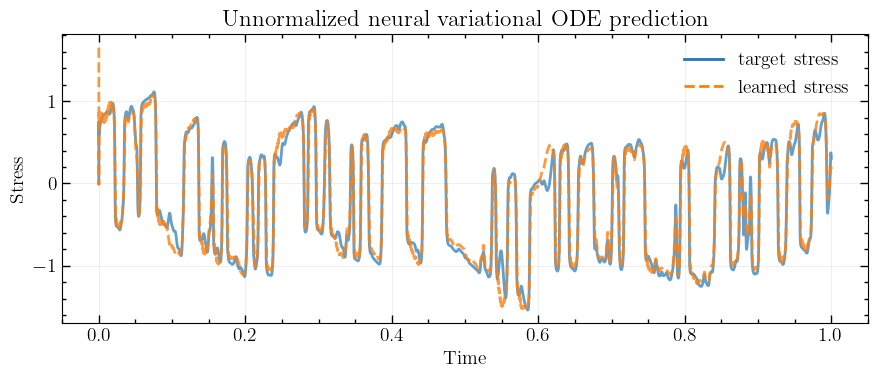

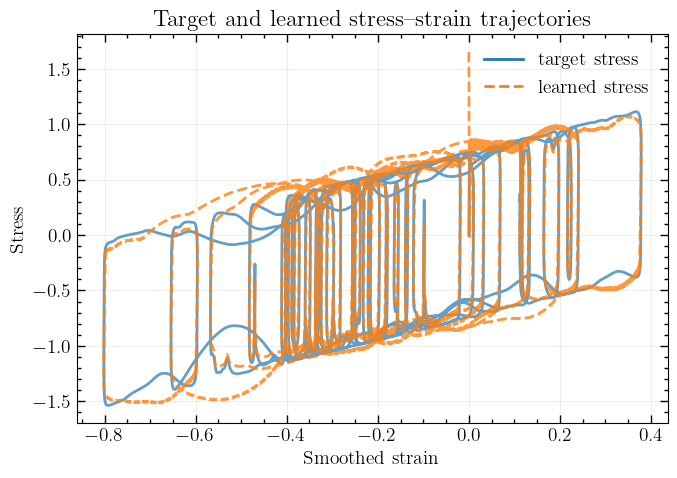

In [39]:
fig_time, ax_time = plt.subplots(figsize=(9, 4))
fig_strain, ax_strain = plt.subplots(figsize=(7, 5))
for trajectory_index in range(3, 4):
    ax_time.plot(times, stress_trajectories[trajectory_index], color="tab:blue", alpha=0.7)
    ax_time.plot(times, stress_learned[trajectory_index], color="tab:orange", linestyle="--", alpha=0.8)
    ax_strain.plot(strain_trajectories_smooth[trajectory_index], stress_trajectories[trajectory_index], color="tab:blue", alpha=0.7)
    ax_strain.plot(strain_trajectories_smooth[trajectory_index], stress_learned[trajectory_index], color="tab:orange", linestyle="--", alpha=0.8)
ax_time.plot([], [], color="tab:blue", label="target stress")
ax_time.plot([], [], color="tab:orange", linestyle="--", label="learned stress")
ax_time.set_xlabel("Time")
ax_time.set_ylabel("Stress")
ax_time.set_title("Unnormalized neural variational ODE prediction")
ax_time.legend()
ax_time.grid(alpha=0.2)
ax_strain.plot([], [], color="tab:blue", label="target stress")
ax_strain.plot([], [], color="tab:orange", linestyle="--", label="learned stress")
ax_strain.set_xlabel("Smoothed strain")
ax_strain.set_ylabel("Stress")
ax_strain.set_title("Target and learned stress--strain trajectories")
ax_strain.legend()
ax_strain.grid(alpha=0.2)
strain_values = strain_trajectories_smooth[:min(5, n_trajectories)]
stress_values = stress_trajectories[:min(5, n_trajectories)]
learned_stress_values = stress_learned[:min(5, n_trajectories)]
x_min, x_max = strain_values.min(), strain_values.max()
y_min = min(stress_values.min(), learned_stress_values.min())
y_max = max(stress_values.max(), learned_stress_values.max())
# x_margin = 0.05 * max(x_max - x_min, 1e-12)
# y_margin = 0.05 * max(y_max - y_min, 1e-12)
# ax_strain.set_xlim(x_min - x_margin, x_max + x_margin)
# ax_strain.set_ylim(y_min - y_margin, y_max + y_margin)
fig_time.tight_layout()
fig_strain.tight_layout()
plt.show()

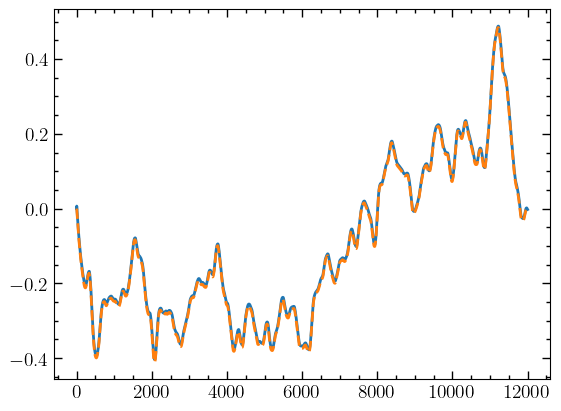

In [41]:
plt.plot(xi_learned[2], label="learned xi")
plt.plot(plastic_strain_trajectories[2], '--', label="target xi")